# Are people still going to the library?

The working behind the [findings report](../findings/README.md), using the Connecticut State Library's statistics for every public library in the state from 1996 to 2024.

The calculations live in [`findings/analysis.py`](../findings/analysis.py) and the charts in [`findings/charts.py`](../findings/charts.py), so this notebook, the report and the tests all share the same code.

In [1]:
import sys
from pathlib import Path

import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "findings").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "findings"))

import analysis as an
import charts

## 0. The data

[`data/prepare.py`](../data/prepare.py) has already tidied the download. Each row is one library in one fiscal year (2024 means July 2023 to June 2024). Renamed libraries share one `library` key, and each has a `town`.

In [2]:
libraries = an.libraries()
libraries.head()

,year,library,name,town,county,wealth_rank,population,visits,borrowers,questions,...,events,attendance,computer_uses,collection,income,town_funding,materials_spending,wages,spending,real_spending
0,1996,andover,Andover,Andover,Tolland,109.0,2815.0,15000.0,1313.0,499.0,...,117.0,860.0,NaN,15285.0,56300.0,52915.0,10073.0,30996.0,44290.0,8.874387e+04
1,1996,ansonia,Ansonia,Ansonia,New Haven,158.0,17825.0,91756.0,6952.0,NaN,...,153.0,4525.0,NaN,63685.0,320679.0,323503.0,45874.0,201621.0,270658.0,5.423174e+05
2,1996,ashfordbabcock,Ashford-Babcock,Ashford,Windham,131.0,3969.0,8665.0,1360.0,207.0,...,22.0,780.0,NaN,23818.0,111699.0,106713.0,11508.0,62295.0,82769.0,1.658442e+05
3,1996,avon,Avon,Avon,Hartford,19.0,14143.0,162893.0,8808.0,15283.0,...,345.0,9501.0,NaN,74903.0,685678.0,602831.0,92711.0,340400.0,516583.0,1.035077e+06
4,1996,beaconfalls,Beacon Falls,Beacon Falls,New Haven,129.0,5351.0,7000.0,1379.0,400.0,...,22.0,223.0,NaN,10042.0,40806.0,39256.0,4298.0,21585.0,39165.0,7.847491e+04


In [3]:
pd.Series(an.data_notes())

names              219.000000
libraries          193.000000
towns              165.000000
rows              5278.000000
missing_2024        10.000000
usual              183.000000
materials_2023       0.090925
materials_2024       0.014892
no_population      464.000000
dtype: float64

Only a town's main library carries its population, and some towns have several libraries. So figures are worked out per town: add up every library, then divide by the town's population.

In [4]:
an.towns().query("town == 'Norwalk' and year in (2019, 2023)")[["year", "town", "population", "visits", "visits_pr"]]

,year,town,population,visits,visits_pr
3881,2019,Norwalk,89047.0,661475.0,7.428381
4541,2023,Norwalk,91401.0,365024.0,3.993654


## 1. Visits were falling long before Covid

Statewide figures per resident, from the towns that reported each year.

In [5]:
an.long_run().round(2)

,visits,loans,attendance,questions,computer_uses
year,,,,,
1996,5.79,7.74,0.32,1.11,NaN
1997,5.69,8.01,0.33,1.15,NaN
1998,5.84,7.99,0.34,1.16,NaN
1999,5.80,7.84,0.35,1.13,NaN
2000,5.98,8.14,0.35,1.09,NaN
2001,6.04,8.09,0.38,1.05,NaN
2002,6.34,8.57,0.37,1.13,NaN
2003,6.50,8.99,0.38,1.15,NaN
2004,6.42,8.96,0.39,1.21,NaN


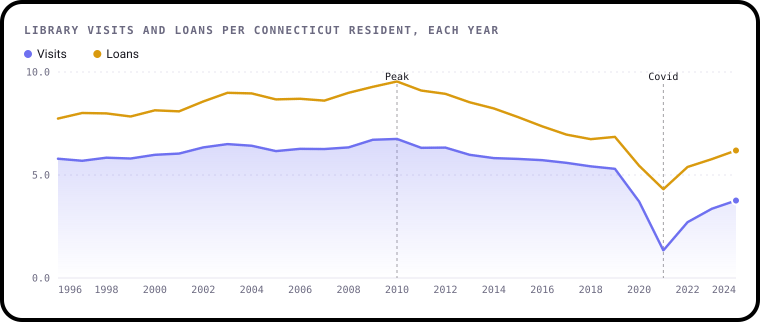

In [6]:
charts.visits()

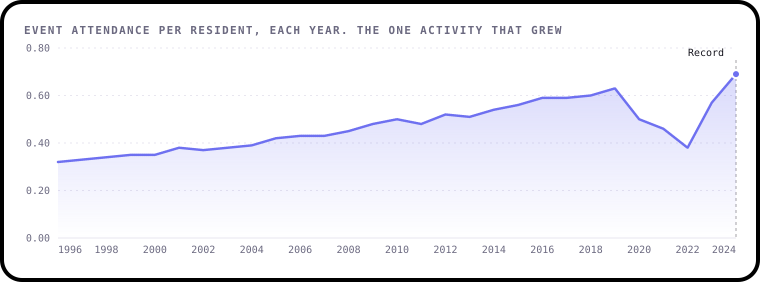

In [7]:
charts.events()

## 2. What came back after Covid

Each activity per resident in 2024, as a share of 2019.

In [8]:
an.recovery().round(3).to_frame("2024 vs 2019")

,2024 vs 2019
Event attendance,1.091
Loans,0.904
Visits,0.710
Questions for staff,0.640
Public computer use,0.342


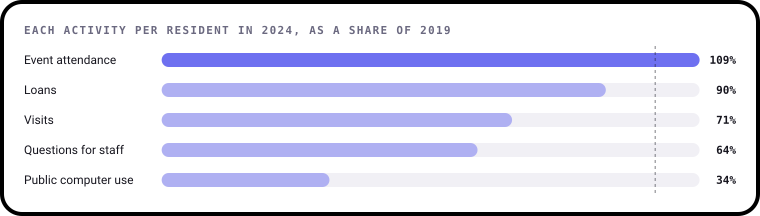

In [9]:
charts.what_came_back()

## 3. Richer towns and poorer towns

Towns are split into four equal groups by their 2019 wealth rank (1 is the richest). Only towns with figures in both years are used, so the comparison isn't affected by which libraries reported.

In [10]:
an.by_wealth().round(3)

,2019,2024,kept
wealth_rank,,,
Richest quarter,7.924,6.748,0.852
Second,6.272,4.213,0.672
Third,5.013,3.480,0.694
Poorest quarter,3.592,2.281,0.635


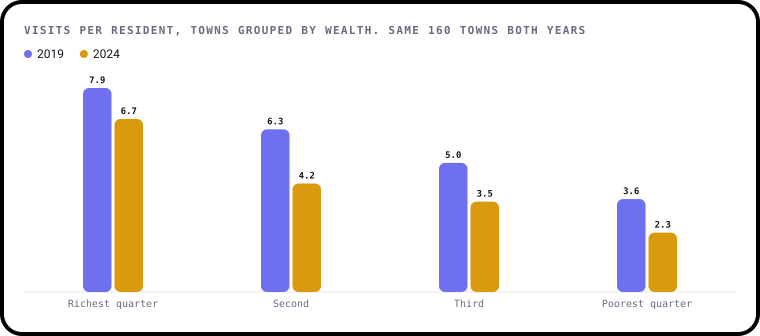

In [11]:
charts.wealth_gap()

## 4. Spending and use

A correlation shows the two move together. It can't show which causes which.

In [12]:
an.spending_link()

{'r': np.float64(0.7580533635175117),
 'rank_r': np.float64(0.7180736732617234),
 'towns': 162}

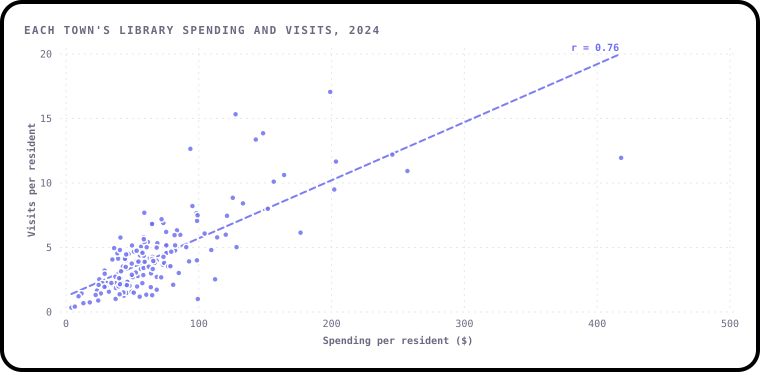

In [13]:
charts.spending_and_visits()

## 5. What libraries cost, in 2024 dollars

Prices come from the US Consumer Price Index, averaged over each July to June fiscal year in `data/prices.csv`.

In [14]:
an.cost().round(2)

,per_resident,per_visit
year,,
1996,51.77,8.94
1997,54.01,9.49
1998,55.84,9.56
1999,57.91,9.99
2000,68.99,11.53
2001,58.40,9.67
2002,60.20,9.49
2003,68.67,10.57
2004,67.19,10.47


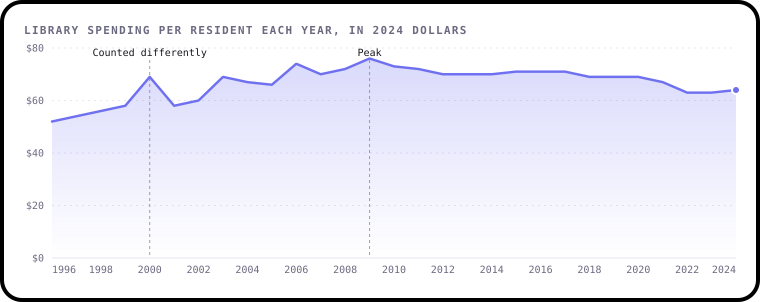

In [15]:
charts.cost()

## 6. The first version's model

The original notebook predicted `Library Visits Per Capita Served` from every numeric column, including one it made itself: visits divided by population. That's the target, worked out again.

In [16]:
an.first_version()

{'copied': 0.9947669053739253,
 'printed_rmse': 0.0725,
 'true_rmse': 0.2692582403567252,
 'match': np.float64(0.9992849817394832),
 'rows_kept': 2965,
 'rows': 5278,
 'first_year': 2005}

## 7. A fair test

Each method learns from 2010 to 2017 and predicts each town's visits per resident in 2019. `explained` is R², the share of the differences between towns a method accounts for. `error` is how far off it is on average, in visits per resident.

In [17]:
an.models().round(3)

,explained,error,towns
The state's typical town,-0.000,2.628,163
Town wealth,0.278,2.318,163
"Wealth, spending and size",0.595,1.709,163
The town's own figure last year,0.904,0.557,161


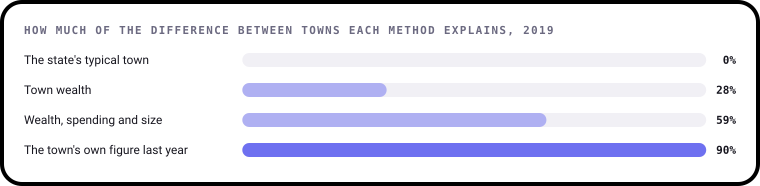

In [18]:
charts.model_scores()

## What this can't tell you

The data shows patterns, not causes, and only for Connecticut. It says nothing about who uses libraries, and registered borrower counts may fall when libraries clear out old records. The [findings report](../findings/README.md) has the full list.